# 🧓 Rede Saber 60+ — Consumo da API SIDRA/IBGE (Censo 2022)
## UF: Mato Grosso (MT)

**Objetivo:** Consumir a API pública do IBGE (SIDRA) para obter dados de população idosa (65+) por município do Mato Grosso, organizando os resultados em DataFrames.

**Fonte:** IBGE — Censo Demográfico 2022 — Tabela 9514
*(População residente, por sexo, idade e forma de declaração da idade)*

**API:** https://apisidra.ibge.gov.br

> A lógica de consumo por blocos (paginação) segue o padrão aprendido na aula de Compras Governamentais.

## 1. Bibliotecas

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
import json

## 2. Configuração da API SIDRA

A API SIDRA utiliza URLs com parâmetros no caminho (path parameters), diferente da API de Compras que usa query parameters.

**Estrutura:**
```
https://apisidra.ibge.gov.br/values/t/{tabela}/n{nivel}/{territorial}/v/{variavel}/p/{periodo}/c{classificacao}/{categorias}
```

**Parâmetros que usaremos:**
- `t/9514` — Tabela 9514 (População residente por sexo e idade)
- `n6/in n3 51` — Nível municipal (`n6`), filtrado pelo estado MT (código `51`)
- `v/93` — Variável: População residente
- `p/2022` — Período: Censo 2022
- `c2/6794` — Sexo: Total
- `c287/
{codigos}` — Faixas etárias
- `f/n` — Formato numérico

In [2]:
BASE_URL = "https://apisidra.ibge.gov.br/values"

# Tabela do Censo 2022 - Populacao residente por sexo e idade
TABELA = "9514"

# UF: Mato Grosso = codigo IBGE 51
UF_CODIGO = "51"

# Codigos das faixas etarias 65+ na classificacao c287
FAIXAS_65_MAIS = {
    "93096": "65 a 69 anos",
    "93097": "70 a 74 anos",
    "93098": "75 a 79 anos",
    "49108": "80 a 84 anos",
    "49109": "85 a 89 anos",
    "60040": "90 a 94 anos",
    "60041": "95 a 99 anos",
    "6653":  "100 anos ou mais"
}

# Codigo para populacao total (todas as idades)
CODIGO_TOTAL = "100362"

print("Faixas etarias 65+:")
for cod, nome in FAIXAS_65_MAIS.items():
    print(f"  {cod}: {nome}")

Faixas etarias 65+:
  93096: 65 a 69 anos
  93097: 70 a 74 anos
  93098: 75 a 79 anos
  49108: 80 a 84 anos
  49109: 85 a 89 anos
  60040: 90 a 94 anos
  60041: 95 a 99 anos
  6653: 100 anos ou mais


## 3. Função de consumo da API por blocos

Assim como na aula de Compras Governamentais, vamos consumir a API em **blocos** (chunks).

A API SIDRA não usa paginação clássica (`pagina=1, 2, 3...`), mas podemos dividir a consulta em blocos de faixas etárias para:
1. Evitar timeout em requisições muito grandes
2. Controlar o que está sendo baixado
3. Ter resiliência (se um bloco falhar, os outros já estão salvos)

In [3]:
def consultar_sidra_bloco(tabela, uf_codigo, codigos_idade, variavel="93", periodo="2022"):
    """
    Consulta a API SIDRA por um bloco de codigos de faixa etaria.
    
    Parametros
    ----------
    tabela : str
        Numero da tabela SIDRA
    uf_codigo : str
        Codigo IBGE da UF
    codigos_idade : list
        Lista de codigos c287 para as faixas etarias
    variavel : str
        Codigo da variavel (93 = populacao residente)
    periodo : str
        Ano de referencia
    
    Retorna
    -------
    list
        Registros JSON da resposta (sem o header)
    """
    
    # Monta a string de codigos separados por virgula
    ids_idade = ",".join(codigos_idade)
    
    # Monta a URL completa
    url = (
        f"{BASE_URL}"
        f"/t/{tabela}"
        f"/n6/in%20n3%20{uf_codigo}"
        f"/v/{variavel}"
        f"/p/{periodo}"
        f"/c2/6794"           # Sexo = Total
        f"/c287/{ids_idade}"
        f"/f/n"               # Formato numerico
    )
    
    print(f"  Consultando: {ids_idade}")
    print(f"  URL: {url}")
    
    resposta = requests.get(url, timeout=120)
    resposta.raise_for_status()
    
    dados = resposta.json()
    
    # O primeiro registro eh o header (nomes das colunas)
    # Retornamos apenas os dados (a partir do indice 1)
    registros = dados[1:] if len(dados) > 1 else []
    
    print(f"  -> {len(registros)} registros obtidos")
    
    return registros


# Teste rapido com um bloco
teste = consultar_sidra_bloco(TABELA, UF_CODIGO, ["93096"])
print("\nExemplo de registro:")
print(json.dumps(teste[0], ensure_ascii=False, indent=2))

  Consultando: 93096
  URL: https://apisidra.ibge.gov.br/values/t/9514/n6/in%20n3%2051/v/93/p/2022/c2/6794/c287/93096/f/n
  -> 141 registros obtidos

Exemplo de registro:
{
  "NN": "Município",
  "MN": "Pessoas",
  "V": "270",
  "D1N": "Acorizal - MT",
  "D2N": "População residente",
  "D3N": "2022",
  "D4N": "Total",
  "D5N": "65 a 69 anos",
  "D6N": "Total"
}


## 4. Coleta completa por blocos (idosos 65+)

Agora vamos iterar por **cada faixa etária como um bloco separado**, coletar os dados e acumular tudo em uma lista única — exatamente como a função `coletar_paginas()` da aula.

In [4]:
def coletar_por_blocos(tabela, uf_codigo, faixas_etarias, pausa=2):
    """
    Coleta dados da API SIDRA em blocos (um por faixa etaria).
    Equivalente a coletar_paginas da aula de Compras Governamentais.
    
    Parametros
    ----------
    tabela : str
        Numero da tabela
    uf_codigo : str
        Codigo da UF
    faixas_etarias : dict
        Dicionario {codigo: nome} das faixas
    pausa : int
        Segundos entre requisicoes (respeitar a API)
    
    Retorna
    -------
    pd.DataFrame
        DataFrame com todos os registros
    """
    todos_registros = []
    
    codigos = list(faixas_etarias.keys())
    total_blocos = len(codigos)
    
    print(f"Iniciando coleta de {total_blocos} blocos...")
    print("=" * 60)
    
    for i, codigo in enumerate(codigos, 1):
        nome_faixa = faixas_etarias[codigo]
        print(f"\nBloco {i}/{total_blocos}: {nome_faixa}")
        
        try:
            registros = consultar_sidra_bloco(tabela, uf_codigo, [codigo])
            todos_registros.extend(registros)
            print(f"  Acumulado: {len(todos_registros)} registros")
        except Exception as e:
            print(f"  ERRO no bloco {i}: {e}")
        
        # Pausa entre requisicoes para nao sobrecarregar a API
        if i < total_blocos:
            print(f"  Aguardando {pausa}s...")
            time.sleep(pausa)
    
    print("\n" + "=" * 60)
    print(f"Coleta finalizada! Total: {len(todos_registros)} registros")
    
    # Converte para DataFrame
    df = pd.DataFrame(todos_registros)
    
    return df


# Executar a coleta completa
df_idosos = coletar_por_blocos(TABELA, UF_CODIGO, FAIXAS_65_MAIS, pausa=2)

print("\nDimensao:", df_idosos.shape)
df_idosos.head()

Iniciando coleta de 8 blocos...

Bloco 1/8: 65 a 69 anos
  Consultando: 93096
  URL: https://apisidra.ibge.gov.br/values/t/9514/n6/in%20n3%2051/v/93/p/2022/c2/6794/c287/93096/f/n
  -> 141 registros obtidos
  Acumulado: 141 registros
  Aguardando 2s...

Bloco 2/8: 70 a 74 anos
  Consultando: 93097
  URL: https://apisidra.ibge.gov.br/values/t/9514/n6/in%20n3%2051/v/93/p/2022/c2/6794/c287/93097/f/n
  -> 141 registros obtidos
  Acumulado: 282 registros
  Aguardando 2s...

Bloco 3/8: 75 a 79 anos
  Consultando: 93098
  URL: https://apisidra.ibge.gov.br/values/t/9514/n6/in%20n3%2051/v/93/p/2022/c2/6794/c287/93098/f/n
  -> 141 registros obtidos
  Acumulado: 423 registros
  Aguardando 2s...

Bloco 4/8: 80 a 84 anos
  Consultando: 49108
  URL: https://apisidra.ibge.gov.br/values/t/9514/n6/in%20n3%2051/v/93/p/2022/c2/6794/c287/49108/f/n
  -> 141 registros obtidos
  Acumulado: 564 registros
  Aguardando 2s...

Bloco 5/8: 85 a 89 anos
  Consultando: 49109
  URL: https://apisidra.ibge.gov.br/values

,NN,MN,V,D1N,D2N,D3N,D4N,D5N,D6N
0,Município,Pessoas,270,Acorizal - MT,População residente,2022,Total,65 a 69 anos,Total
1,Município,Pessoas,780,Água Boa - MT,População residente,2022,Total,65 a 69 anos,Total
2,Município,Pessoas,1904,Alta Floresta - MT,População residente,2022,Total,65 a 69 anos,Total
3,Município,Pessoas,643,Alto Araguaia - MT,População residente,2022,Total,65 a 69 anos,Total
4,Município,Pessoas,140,Alto Boa Vista - MT,População residente,2022,Total,65 a 69 anos,Total


## 5. Coletar população total por município (bloco único)

Para calcular indicadores como o **percentual de idosos**, precisamos também da população total.

In [ ]:
print("Coletando populacao total por municipio...")
registros_total = consultar_sidra_bloco(
    TABELA, UF_CODIGO, [CODIGO_TOTAL]
)
df_pop_total = pd.DataFrame(registros_total)
print("\nDimensao:", df_pop_total.shape)
df_pop_total.head()

Coletando populacao total por municipio...
  Consultando: 100362
  URL: https://apisidra.ibge.gov.br/values/t/9514/n6/in%20n3%2051/v/93/p/2022/c2/6794/c287/100362/f/n
  -> 141 registros obtidos

Dimensao: (141, 9)


,NN,MN,V,D1N,D2N,D3N,D4N,D5N,D6N
0,Município,Pessoas,5014,Acorizal - MT,População residente,2022,Total,Total,Total
1,Município,Pessoas,29219,Água Boa - MT,População residente,2022,Total,Total,Total
2,Município,Pessoas,58613,Alta Floresta - MT,População residente,2022,Total,Total,Total
3,Município,Pessoas,17193,Alto Araguaia - MT,População residente,2022,Total,Total,Total
4,Município,Pessoas,5715,Alto Boa Vista - MT,População residente,2022,Total,Total,Total


## 6. Limpeza e transformação dos dados

### 6.1 Renomear colunas
A API SIDRA retorna colunas com nomes codificados. Vamos renomear para facilitar a análise.

In [6]:
# Mapeamento de colunas
COLUNAS_RENOMEAR = {
    "V": "valor",
    "D1N": "municipio",
    "D2N": "variavel",
    "D3N": "ano",
    "D4N": "sexo",
    "D5N": "faixa_etaria",
    "D6N": "forma_declaracao",
    "NN": "nivel_territorial",
    "MN": "unidade_medida"
}

# Aplicar renomeacao
df_idosos = df_idosos.rename(columns=COLUNAS_RENOMEAR)
df_pop_total = df_pop_total.rename(columns=COLUNAS_RENOMEAR)

print("Colunas df_idosos:", list(df_idosos.columns))
print("Colunas df_pop_total:", list(df_pop_total.columns))

Colunas df_idosos: ['nivel_territorial', 'unidade_medida', 'valor', 'municipio', 'variavel', 'ano', 'sexo', 'faixa_etaria', 'forma_declaracao']
Colunas df_pop_total: ['nivel_territorial', 'unidade_medida', 'valor', 'municipio', 'variavel', 'ano', 'sexo', 'faixa_etaria', 'forma_declaracao']


In [7]:
# Converter valor para numerico
df_idosos["valor"] = pd.to_numeric(df_idosos["valor"], errors="coerce")
df_pop_total["valor"] = pd.to_numeric(df_pop_total["valor"], errors="coerce")

# Extrair apenas o nome do municipio (sem " - MT")
df_idosos["municipio_nome"] = df_idosos["municipio"].str.replace(" - MT", "", regex=False)
df_pop_total["municipio_nome"] = df_pop_total["municipio"].str.replace(" - MT", "", regex=False)

print("Tipos de dados:")
print(df_idosos.dtypes)

Tipos de dados:
nivel_territorial        str
unidade_medida           str
valor                float64
municipio                str
variavel                 str
ano                      str
sexo                     str
faixa_etaria             str
forma_declaracao         str
municipio_nome           str
dtype: object


### 6.2 Verificar dados ausentes e duplicidades

In [9]:
print("=== Idosos 65+ ===")
print("Linhas duplicadas:", df_idosos.duplicated().sum())
print("\nValores ausentes (%):")
print(df_idosos.isna().mean().mul(100).round(2))

print("\n=== Populacao Total ===")
print("Linhas duplicadas:", df_pop_total.duplicated().sum())
print("\nValores ausentes (%):")
print(df_pop_total.isna().mean().mul(100).round(2))

=== Idosos 65+ ===
Linhas duplicadas: 0

Valores ausentes (%):
nivel_territorial    0.00
unidade_medida       0.00
valor                5.14
municipio            0.00
variavel             0.00
ano                  0.00
sexo                 0.00
faixa_etaria         0.00
forma_declaracao     0.00
municipio_nome       0.00
dtype: float64

=== Populacao Total ===
Linhas duplicadas: 0

Valores ausentes (%):
nivel_territorial    0.0
unidade_medida       0.0
valor                0.0
municipio            0.0
variavel             0.0
ano                  0.0
sexo                 0.0
faixa_etaria         0.0
forma_declaracao     0.0
municipio_nome       0.0
dtype: float64


## 7. Análise: Total de idosos 65+ por município

Vamos agrupar os dados por município, somando todas as faixas etárias 65+.

In [10]:
# Somar todas as faixas 65+ por municipio
df_idosos_municipio = (
    df_idosos
    .groupby("municipio_nome")["valor"]
    .sum()
    .reset_index()
    .rename(columns={"valor": "pop_65_mais"})
)

# Juntar com populacao total
df_pop = df_pop_total[["municipio_nome", "valor"]].rename(
    columns={"valor": "pop_total"}
)

df_completo = df_idosos_municipio.merge(df_pop, on="municipio_nome", how="left")

# Calcular percentual de idosos
df_completo["pct_idosos"] = (
    df_completo["pop_65_mais"] / df_completo["pop_total"] * 100
).round(2)

# Ordenar por percentual
df_completo = df_completo.sort_values("pct_idosos", ascending=False).reset_index(drop=True)

print(f"Municipios analisados: {len(df_completo)}")
print(f"Populacao total MT: {df_completo['pop_total'].sum():,.0f}")
print(f"Idosos 65+ MT: {df_completo['pop_65_mais'].sum():,.0f}")
print(f"Percentual medio de idosos: {df_completo['pct_idosos'].mean():.2f}%")

df_completo.head(15)

Municipios analisados: 141
Populacao total MT: 3,658,649
Idosos 65+ MT: 282,040
Percentual medio de idosos: 8.90%


,municipio_nome,pop_65_mais,pop_total,pct_idosos
0,São José do Povo,543.0,2875,18.89
1,Araguainha,164.0,1010,16.24
2,Guiratinga,1779.0,10966,16.22
3,Ponte Branca,316.0,2008,15.74
4,Acorizal,769.0,5014,15.34
5,Glória D'Oeste,436.0,2905,15.01
6,Torixoréu,625.0,4164,15.01
7,Nossa Senhora do Livramento,1886.0,12940,14.57
8,Dom Aquino,1116.0,7872,14.18
9,Porto Estrela,450.0,3224,13.96


## 8. Estatística descritiva

In [11]:
df_completo[["pop_total", "pop_65_mais", "pct_idosos"]].describe().T

,count,mean,std,min,25%,50%,75%,max
pop_total,141.0,25947.865248,65942.369900,1010.00,4903.00,10332.00,20091.00,650877.00
pop_65_mais,141.0,2000.283688,5375.841088,149.00,449.00,869.00,1703.00,56258.00
pct_idosos,141.0,8.899362,3.108373,2.58,6.74,8.55,10.75,18.89


## 9. Visualizações

### 9.1 Top 20 municípios com maior percentual de idosos

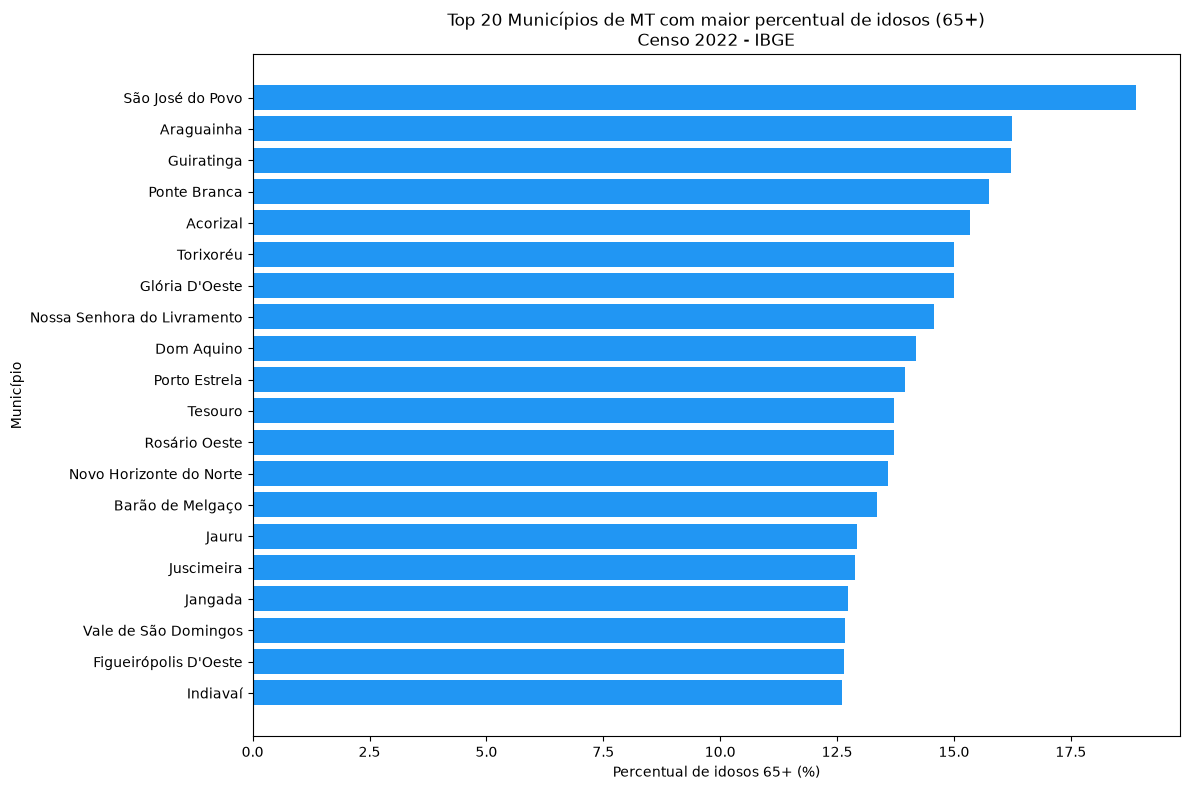

In [12]:
top20 = df_completo.nlargest(20, "pct_idosos").sort_values("pct_idosos")

plt.figure(figsize=(12, 8))
plt.barh(top20["municipio_nome"], top20["pct_idosos"], color="#2196F3")
plt.xlabel("Percentual de idosos 65+ (%)")
plt.ylabel("Município")
plt.title("Top 20 Municípios de MT com maior percentual de idosos (65+)\nCenso 2022 - IBGE")
plt.tight_layout()
plt.show()

### 9.2 Distribuição dos idosos por faixa etária em todo o MT

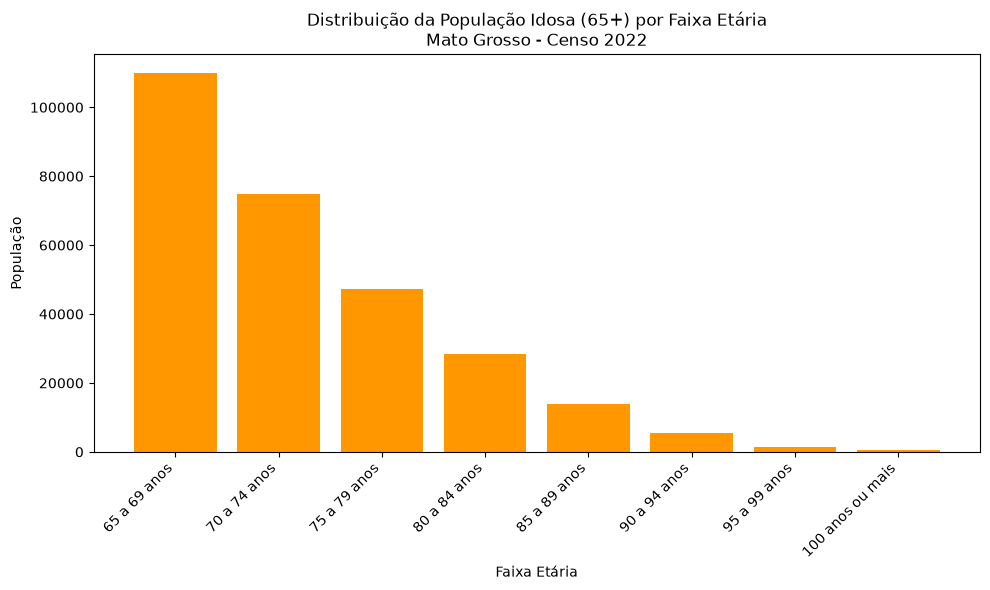


Resumo por faixa etaria:
    faixa_etaria    valor
    65 a 69 anos 109968.0
    70 a 74 anos  74788.0
    75 a 79 anos  47331.0
    80 a 84 anos  28512.0
    85 a 89 anos  13980.0
    90 a 94 anos   5513.0
    95 a 99 anos   1456.0
100 anos ou mais    492.0


In [13]:
# Agrupar por faixa etaria
df_faixas = (
    df_idosos
    .groupby("faixa_etaria")["valor"]
    .sum()
    .reset_index()
    .sort_values("valor", ascending=False)
)

plt.figure(figsize=(10, 6))
plt.bar(df_faixas["faixa_etaria"], df_faixas["valor"], color="#FF9800")
plt.xlabel("Faixa Etária")
plt.ylabel("População")
plt.title("Distribuição da População Idosa (65+) por Faixa Etária\nMato Grosso - Censo 2022")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nResumo por faixa etaria:")
print(df_faixas.to_string(index=False))

### 9.3 Top 20 municípios com maior número absoluto de idosos

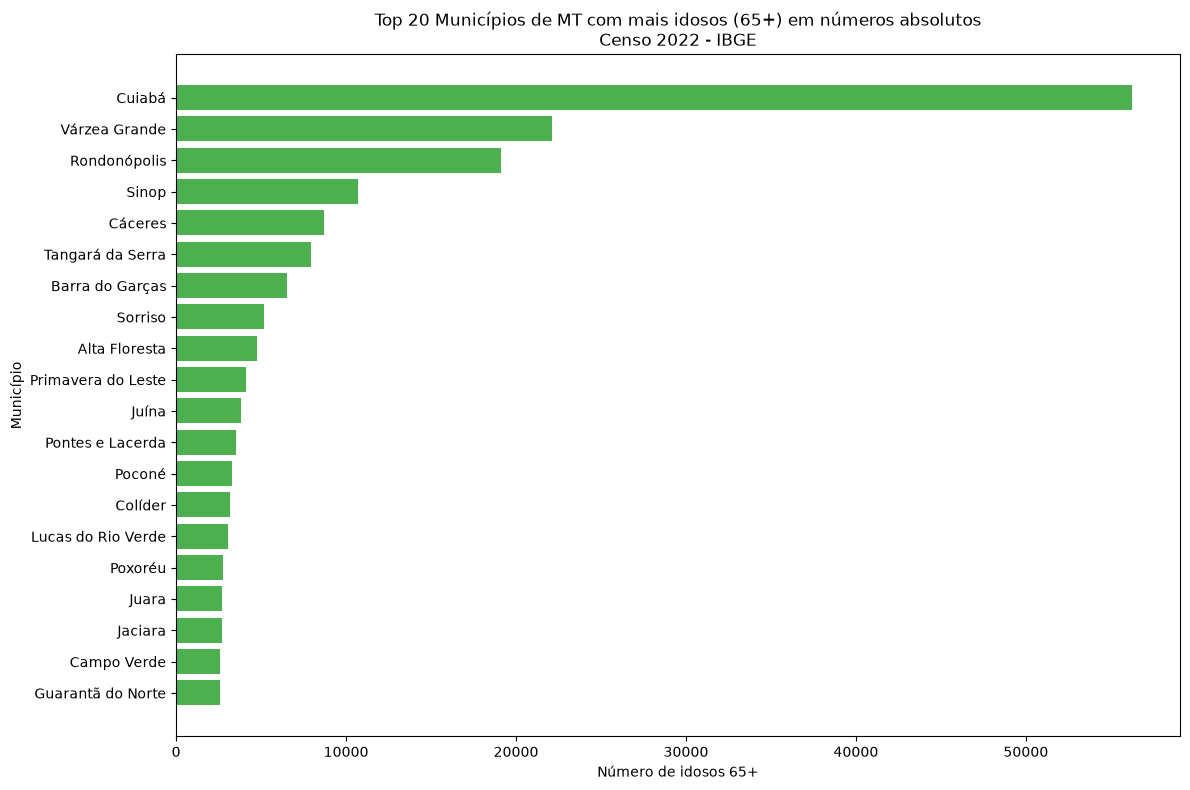

In [14]:
top20_abs = df_completo.nlargest(20, "pop_65_mais").sort_values("pop_65_mais")

plt.figure(figsize=(12, 8))
plt.barh(top20_abs["municipio_nome"], top20_abs["pop_65_mais"], color="#4CAF50")
plt.xlabel("Número de idosos 65+")
plt.ylabel("Município")
plt.title("Top 20 Municípios de MT com mais idosos (65+) em números absolutos\nCenso 2022 - IBGE")
plt.tight_layout()
plt.show()

### 9.4 Boxplot do percentual de idosos por município

C:\Users\52068085801\AppData\Local\Temp\ipykernel_22624\1073988874.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_completo["pct_idosos"].dropna(), vert=False, patch_artist=True,


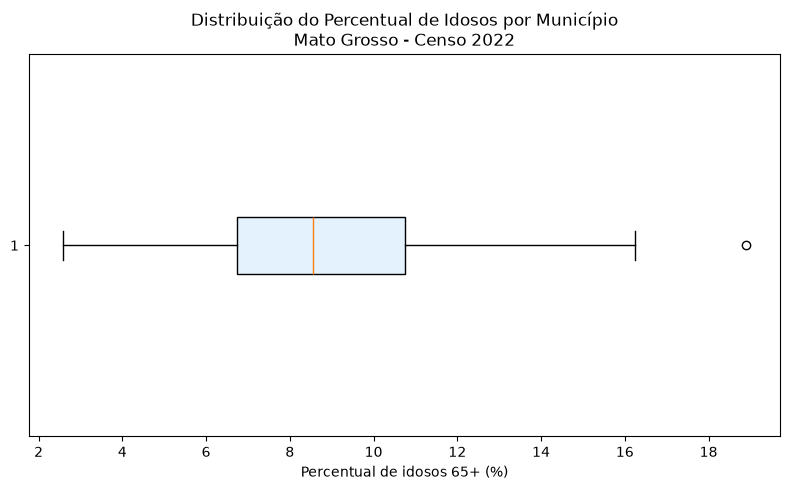

Municipios com maior envelhecimento (acima do P75):
Percentil 75: 10.75%
             municipio_nome  pct_idosos  pop_65_mais  pop_total
           São José do Povo       18.89        543.0       2875
                 Araguainha       16.24        164.0       1010
                 Guiratinga       16.22       1779.0      10966
               Ponte Branca       15.74        316.0       2008
                   Acorizal       15.34        769.0       5014
             Glória D'Oeste       15.01        436.0       2905
                  Torixoréu       15.01        625.0       4164
Nossa Senhora do Livramento       14.57       1886.0      12940
                 Dom Aquino       14.18       1116.0       7872
              Porto Estrela       13.96        450.0       3224
                    Tesouro       13.72        415.0       3025
              Rosário Oeste       13.71       2118.0      15453
    Novo Horizonte do Norte       13.59        455.0       3349
           Barão de Melgaço    

In [15]:
plt.figure(figsize=(8, 5))
plt.boxplot(df_completo["pct_idosos"].dropna(), vert=False, patch_artist=True,
            boxprops=dict(facecolor="#E3F2FD"))
plt.xlabel("Percentual de idosos 65+ (%)")
plt.title("Distribuição do Percentual de Idosos por Município\nMato Grosso - Censo 2022")
plt.tight_layout()
plt.show()

print("Municipios com maior envelhecimento (acima do P75):")
p75 = df_completo["pct_idosos"].quantile(0.75)
print(f"Percentil 75: {p75:.2f}%")
print(df_completo[df_completo["pct_idosos"] >= p75][["municipio_nome", "pct_idosos", "pop_65_mais", "pop_total"]].to_string(index=False))

## 10. Exportar dados para uso posterior

Os DataFrames gerados podem ser salvos em CSV para uso em outras etapas do projeto (modelo de dados, dashboard, etc.).

In [16]:
# Salvar CSVs
df_completo.to_csv("idosos_65mais_municipios_MT_censo2022.csv", index=False, encoding="utf-8-sig")
df_idosos.to_csv("idosos_65mais_faixas_MT_censo2022.csv", index=False, encoding="utf-8-sig")

print("Arquivos salvos:")
print("  - idosos_65mais_municipios_MT_censo2022.csv")
print("  - idosos_65mais_faixas_MT_censo2022.csv")
print("\nPronto para uso no Observatorio e no modelo de dados!")

Arquivos salvos:
  - idosos_65mais_municipios_MT_censo2022.csv
  - idosos_65mais_faixas_MT_censo2022.csv

Pronto para uso no Observatorio e no modelo de dados!


## 11. Resumo da Fonte de Dados

| Campo | Valor |
|-------|-------|
| **Fonte** | IBGE — Censo Demográfico 2022 |
| **API** | SIDRA (`apisidra.ibge.gov.br`) |
| **Tabela** | 9514 |
| **Variável** | 93 (População residente) |
| **Classificação** | c287 (Idade) |
| **Nível territorial** | Municípios (n6) |
| **UF** | Mato Grosso (51) |
| **Período** | 2022 |
| **Acesso** | Aberto (sem autenticação) |
| **Formato** | JSON |
| **Frequência** | Decenal (Censo) |